# Wu–Shaknov's experiment: coincidence asymmetry computed from two-photon quantum states

#### by Pablo Ribera Manzano, Biel Pons Zaragozà and Sebastià Salazar Giner

The code in this notebook computes the ratio $N_\perp/N_\parallel$ measured by Wu & Shaknov starting from a quantum state, using only the Born rule. 

**The only two inputs:**
1. A two-photon polarization state $\rho$, built with Qiskit. Polarization is a qubit: $|H\rangle=|0\rangle$ (along $x$), $|V\rangle=|1\rangle$ (along $y$).
2. The single-photon Klein–Nishina law: how one photon with a given polarization scatters. 

The coincidence probability is then the Born rule: $P = \mathrm{Tr}\left[\rho\,(E_1\otimes E_2)\right]$.


This notebook includes small scripts that allow to perform certain checks for better understanding of the code. They can be skipped if you are only interested in the results.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, DensityMatrix, Operator, concurrence, partial_trace
from matplotlib.lines import Line2D

RNG = np.random.default_rng(1234)   # fixed seed: same random numbers every run
DEG = np.pi / 180                   # degree -> radians conversion
I2 = np.eye(2)                      # identity
t82 = 82 * DEG                      # scattering angle of maximum probability (in radians)

## 1. Two-photon states (Qiskit)

Photon 1 = qubit 0, photon 2 = qubit 1, both described in the same lab $x,y$ axes.

| State | Meaning |
|---|---|
| $(\lvert HV\rangle - \lvert VH\rangle)/\sqrt{2}$ | entangled, perpendicular polarizations |
| $\lvert R\rangle\lvert L\rangle$ | product of circular polarizations. Bohm–Aharonov's hypothesis B1|
| $\lvert H\rangle\lvert V\rangle$ | product state, perpendicular polarizations Bohm–Aharonov hypothesis B2 |

In [2]:
def circuit_state(build):
    qc = QuantumCircuit(2)
    build(qc)
    return DensityMatrix(Statevector(qc))


def singlet(qc):      # (|H V> - |V H>)/sqrt2
    # Begins at |H H>
    qc.h(0);        # Applies Hadamard, (|HH> + |VH>)/sqrt(2)
    qc.cx(0, 1);    # Applies CNOT, (|HH> + |VV>)/sqrt(2)
    qc.x(1);        # Applies X to photon 2,  (|HV> + |VH>)/sqrt(2)
    qc.z(0)         # Applies Z to photon 1,  (|HV> - |VH>)/sqrt(2)


def product_HV(qc):   # |H V>
    # Begins at |H H>
    qc.x(1)        # Applies X to photon 2, |H V>


def product_RL(qc):   # |R L>: circular polarizations
    # Begins at |H H>
    qc.h(0)           # Hadamard on photon 1: (|H> + |V>)/sqrt(2) x |H>,
    qc.s(0)           # S on photon 1: (|H> + i|V>)/sqrt(2) x |H> = |R> x |H>
    qc.h(1)           # Hadamard on photon 2: |R> x (|H> + |V>)/sqrt(2)
    qc.sdg(1)         # S-dagger on photon 2: |R> x (|H> - i|V>)/sqrt(2) = |RL>



### Check 1a: each state as a vector

Note: Qiskit writes labels right to left (qubit 1, then qubit 0). So 10 = photon 2 is V, photon 1 is H, therefore it is the state $|H\rangle_1|V\rangle_2$ 

In [3]:
for f in (singlet, product_HV, product_RL):
    qc = QuantumCircuit(2); f(qc)
    sv = Statevector(qc).to_dict()
    print(f"{f.__name__:11s}", {str(k): complex(round(v.real, 3), round(v.imag, 3)) for k, v in sv.items()})

singlet     {'01': (-0.707+0j), '10': (0.707+0j)}
product_HV  {'10': (1+0j)}
product_RL  {'00': (0.5+0j), '01': 0.5j, '10': -0.5j, '11': (0.5+0j)}


### Check 1b: each photon on its own
We can trace out one photon for each state to check the density operator of a single photon.

singlet → each photon is $I/2$ (completely unpolarized); 
product $|H\rangle|V\rangle$ → photon 1 is pure $|H\rangle$.

In [4]:

print("Singlet:")
rho = circuit_state(singlet)
print("photon 1 alone:\n", np.round(partial_trace(rho, [1]).data.real, 3), "\n")
print("photon 2 alone:\n", np.round(partial_trace(rho, [0]).data.real, 3), "\n")

print()

print("Product HV:")
rho = circuit_state(product_HV)
print("photon 1 alone:\n", np.round(partial_trace(rho, [1]).data.real, 3), "\n")
print("photon 2 alone:\n", np.round(partial_trace(rho, [0]).data.real, 3), "\n")

Singlet:
photon 1 alone:
 [[0.5 0. ]
 [0.  0.5]] 

photon 2 alone:
 [[0.5 0. ]
 [0.  0.5]] 


Product HV:
photon 1 alone:
 [[1. 0.]
 [0. 0.]] 

photon 2 alone:
 [[0. 0.]
 [0. 1.]] 



<!-- ## 1. Single-photon physics: Klein–Nishina as a measurement operator

For a photon of polarization $e$ scattered by an angle $\theta$ into azimuth $\varphi$ (summed over the final polarization, unpolarized electrons):

$$\frac{d\sigma}{d\Omega} \propto \left(\frac{k}{k_0}\right)^2\left[\gamma - 2\,|e\cdot k'|^2\right],\qquad e\cdot k' = \sin\theta\,\langle u_\varphi|e\rangle,$$

with $u_\varphi=(\cos\varphi,\sin\varphi)$, $\gamma = k/k_0 + k_0/k$ and $k/k_0 = 1/(2-\cos\theta)$ for 511 keV photons.

As an operator on the polarization qubit: $K(\theta,\varphi) = (k/k_0)^2\left[\gamma\, I - 2\sin^2\theta\, |u_\varphi\rangle\langle u_\varphi|\right]$.

For fixed $\theta$, $E(\varphi) = K / \left[2\pi (k/k_0)^2(\gamma-\sin^2\theta)\right]$ integrates to the identity over $\varphi$, so $\{E(\varphi)\,d\varphi\}$ is a valid quantum measurement (a POVM) whose outcome is the azimuth of the scattered photon. -->

## 2. Single-photon physics: Klein–Nishina as a measurement operator
From Bohm & Aharonov’s paper, the scattering cross section of a single photon from an electron is:
$$K(\theta,\varphi) = (k/k_0)^2\left[\gamma - 2\sin^2\theta \right]\, |u_{\varphi_{\parallel}}\rangle\langle u_{\varphi_{\parallel}}|$$
when the initial polarization direction is parallel to the plane $\pi$.

$$K(\theta,\varphi) = (k/k_0)^2\left(\gamma \right)\, |u_{\varphi_{\perp}}\rangle\langle u_{\varphi_{\perp }}|$$
when the initial polarization direction is perpendicular to the plane $\pi$.

Since $ |u_{\varphi_{\parallel}}\rangle\langle u_{\varphi_{\parallel }}| +  |u_{\varphi_{\perp}}\rangle\langle u_{\varphi_{\perp}}| = I$,

As an operator on the polarization qubit: $K(\theta,\varphi) = (k/k_0)^2\left[\gamma\, I - 2\sin^2\theta\, |u_{\varphi_{\parallel}}\rangle\langle u_{\varphi_{\parallel}}|\right]$.

For fixed $\theta$, we can normalize it integrating over phi: $E(\varphi) = K / \left[2\pi (k/k_0)^2(\gamma-\sin^2\theta)\right]$.

In [5]:
def k_rate(t):
    # k/k0: energy ratio of the Compton-scattered 511 keV photon
    return 1 / (2 - np.cos(t))


# Probability of finding photon at theta, phi (measured on only one photon, not both)
def povm(theta, phi):
    gamma, sin2 = k_rate(theta) + 1 / k_rate(theta), np.sin(theta) ** 2
    u = np.array([np.cos(phi), np.sin(phi)])
    K = gamma * I2 - 2 * sin2 * np.outer(u, u)
    return K / (2 * np.pi * (gamma - sin2))

### Check 2a: is E a valid POVM?
both eigenvalues positive; integral over φ = identity.

In [6]:
E = povm(t82, 30 * DEG)
print("eigenvalues:", np.round(np.linalg.eigvalsh(E), 3))

# Instead of an integral, makes sums over lots of points
phis = np.linspace(0, 2 * np.pi, 1000, endpoint=False)
print("integral of E over phi:\n", np.round(sum(povm(t82, p) for p in phis) * (2 * np.pi / 1000), 3))

eigenvalues: [0.049 0.269]
integral of E over phi:
 [[ 1. -0.]
 [-0.  1.]]


## 3. Born rule and the measured ratio

The Born rule gives the probability that a measurement on a quantum system yields a given result. For a system in the state $\rho$ (density matrix), the probability of outcome $i$ is
$$P(i) = \mathrm{Tr}(\rho\, E_i),$$
where $E_i$ is the measurement operator (POVM element) for that outcome. 

For an ideal measurement $E_i$ is a projector; for Compton scattering it is the Klein–Nishina operator $E(\theta,\varphi)$ of Section 1. For the two photons, the probability that photon 1 scatters at azimuth $\varphi_1$ and photon 2 at $\varphi_2$ is $\mathrm{Tr}[\rho\, E(\varphi_1)\otimes E(\varphi_2)]$.

**Coincidence rates.** Detector 1 sits at azimuth $\psi$, measured from the lab $x$-axis (the $H$ direction), and detector 2 at $\psi + \Delta$. Perpendicular coincidences correspond to $\Delta = 90^\circ, 270^\circ$ and parallel ones to $\Delta = 0^\circ, 180^\circ$:
$$N(\Delta) = \big\langle \mathrm{Tr}[\rho\, E(\psi)\otimes E(\psi+\Delta)]\big\rangle_\psi, \qquad \text{ratio} = \frac{N(90^\circ)+N(270^\circ)}{N(0^\circ)+N(180^\circ)}.$$

**Why average over $\psi$.** The positron source has no preferred direction around the beam axis, so photon pairs are emitted with all orientations equally often. Averaging over the orientation $\psi$ of the apparatus is equivalent. For a rotation-invariant state such as the singlet, the result does not depend on $\psi$. For a state with a fixed axis such as $\lvert H\rangle\lvert V\rangle$, it does (from 0.18 to 5.49), and only the average is physically meaningful.

In [7]:
# Qiskit ordering: qubit 1 (photon 2) is the LEFT factor of the tensor product.

def joint_prob(rho, E1, E2):
    # Born rule: Tr[rho (E1 on photon 1) x (E2 on photon 2)].
    return np.real(np.trace(rho.data @ np.kron(E2, E1)))


def ratio(rho, theta, psis=np.arange(0, 180, 15) * DEG):
    # N_perp / N_par, averaged over different orientation psi

    n = {d: 0.0 for d in (0, 90, 180, 270)}     # Creates an empty list like: [0: 0.0, 90: 0.0, 180: 0.0, 270: 0.0]
    for psi in psis:
        for d in n:
            n[d] += joint_prob(rho, povm(theta, psi), povm(theta, psi + d * DEG))
                                                # The list becomes: [0: n[0], 90: n[90], 180: n[180], 270: n[270]]
                                                # For example:      [0: 10,   90: 8,     180: 20,     270: 1     ]
    return (n[90] + n[270]) / (n[0] + n[180])


### Check 3a: probabilities add up to 1, and photon 1 alone looks random
We set detectors at different degrees and check the joint probability of detecting the two photons for each combination.

If the measurement is well performed, when summed over all combinations, the total probability should be 1. 

When considering just one photon, each detection should have the same probability, since it should be random.

In [8]:
rho = circuit_state(singlet)
# Create 72 detectors over the whole ring, so that they are separated d=5º from each other
ph = np.linspace(0, 2 * np.pi, 72, endpoint=False); d = 2 * np.pi / 72

# Fixing detector a, we sum the joint detection probabilities sweeping the angles of b. We do this for all angles of a. 
P = np.array([[joint_prob(rho, povm(t82, a), povm(t82, b)) for b in ph] for a in ph]) * d * d
# print(P)

# It should give us a total probability of 1.
print("total probability:", round(P.sum(), 6))

# Marginal probability. If random, should give us 1/72 = 0.013889 both for min and for max, since there are 72 detectors.
print("photon 1 alone: \t min:", round(P.sum(axis=1).min(), 6),"\n \t \t \t max:",
      round(P.sum(axis=1).max(), 6))

total probability: 1.0
photon 1 alone: 	 min: 0.013889 
 	 	 	 max: 0.013889


### Check 3b: comparison with literature; Snyder, Pasternack & Hornbostel (1948)
 The Born-rule calculation never uses their formula, $\rho = 1 + 2\sin^4\theta/(\gamma^2 - 2\gamma\sin^2\theta)$, yet it should reproduce it exactly.

In [9]:
rho = circuit_state(singlet)
print(" theta   Born rule   Equation")
for deg in (40, 60, 82, 90, 120):
    t = deg * DEG; gamma, sin2 = k_rate(t) + 1 / k_rate(t), np.sin(t) ** 2
    print(f"{deg:5d}   {ratio(rho, t):9.4f}   {1 + 2 * sin2**2 / (gamma**2 - 2 * gamma * sin2):9.4f}")

 theta   Born rule   Equation
   40      1.1371      1.1371
   60      1.7788      1.7788
   82      2.8353      2.8353
   90      2.6000      2.6000
  120      1.2771      1.2771


## 4. Simulation of the experiment

To recreate the experiment, we simulate it pair by pair, as it would happen in the laboratory. The simulation is split into two functions.

**`run_experiment(rho, theta, nshots)`: the measurement.**
We send `nshots` photon pairs, all in the state $\rho$. Both photons Compton-scatter at the angle $\theta$, and the azimuth $\varphi$ of each scattered photon is drawn at random. The ring of possible azimuths is divided into 360 bins of 1°, and the probability that photon 1 lands in bin $i$ and photon 2 in bin $j$ is given by the Born rule,
$$P(i,j) = \mathrm{Tr}\left[\rho\, E_i \otimes E_j\right],$$
where $E_i$ is the Klein–Nishina measurement operator integrated over bin $i$. The function returns the list of recorded pairs: for each pair, the azimuth bin of photon 1 and of photon 2.

**`analyse(pairs)`: the data analysis.**
For each recorded pair we compute the angle between the two scattered photons, $\Delta\varphi = \varphi_2 - \varphi_1$, and count the coincidences at $\Delta\varphi = 0^\circ, 180^\circ$ (parallel, $N_\parallel$) and $\Delta\varphi = 90^\circ, 270^\circ$ (perpendicular, $N_\perp$), to within the 1° bin width. The function returns the ratio $N_\perp/N_\parallel$ and its statistical error, from Poisson counting statistics:
$$\frac{\delta N}{N} = \sqrt{\frac{1}{N_\perp} + \frac{1}{N_\parallel}}.$$

Because we use the angle *between* the photons, every position of detector 1 around the ring is included, which is the average over the apparatus orientation $\varphi$.

In [10]:
# 'povm' gives a probability DENSITY in phi (probability per radian). 
# To get the probability of landing in a 1-degree bin we can simply multiply by the bin width, using E at the centre of the bin (because the bins are small).

# IMPORTANT: theta is a single value, not a range (no solid angle), so this does not reproduce Wu's finite-geometry value of 2.00.

def run_experiment(rho, theta, nshots, nbins=360):
    """
    One virtual experiment: send nshots photon pairs, record where each pair landed.

    Returns an array of shape (nshots, 2): for each pair, the azimuth bin of
    photon 1 and of photon 2 (with nbins=360, bin k = azimuth between k and k+1 degrees).
    """
    # 1) Divide the ring into nbins slices; measurement operator of each slice
    width = 2 * np.pi / nbins                                 # bin width (1 degree in radians)
    centres = (np.arange(nbins) + 0.5) * width                # centre of each bin
    E = np.array([povm(theta, phi) * width for phi in centres])

    # NEW VERSION: it is the same as joint_prob, but computed in one step (much faster, scripted by an AI) 
    # 2) Born rule for every pair of slices: P[i, j] = probability of finding photon 1 in slice i AND photon 2 in slice j
    r = rho.data.reshape(2, 2, 2, 2)                          # one index per photon: [q1, q0, q1', q0']
    P = np.real(np.einsum("abcd,idb,jca->ij", r, E, E))       # = Tr[rho (E_j x E_i)] for all i, j
    P = (P / P.sum()).ravel()                                 # flat list of nbins*nbins outcome probabilities


    # OLD VERSION: MUCH SLOWER 
    # 2) Born rule for every pair of slices: P[i, j] = probability of finding photon 1 in slice i AND photon 2 in slice j
    # P = np.zeros((nbins, nbins))
    # for i in range(nbins):                         # slice of photon 1
    #     for j in range(nbins):                     # slice of photon 2
    #         P[i, j] = joint_prob(rho, E[i], E[j])  # Born rule: Tr[rho (E_i on photon 1) x (E_j on photon 2)]
    # P = (P / P.sum()).ravel()                      # flat list of nbins*nbins outcome probabilities

    # 3) Each pair independently picks one outcome (i, j) with probability P[i, j]
    outcome = RNG.choice(nbins * nbins, size=nshots, p=P)
    bin1, bin2 = np.divmod(outcome, nbins)                    # outcome number -> (bin of photon 1, bin of photon 2)
    return np.column_stack([bin1, bin2])

def analyse(pairs, nbins=360):
    """
    Ratio N_perp / N_par and its statistical error from a list of recorded pairs.
    """
    # angle between the two photons, in bins (0 ... nbins-1)
    delta = (pairs[:, 1] - pairs[:, 0]) % nbins
    k = nbins // 4                                            # 90 degrees in bins
    N = {d: np.sum(delta == d * k) for d in range(4)}         # coincidences at 0, 90, 180, 270 deg
    par = N[0] + N[2]
    perp = N[1] + N[3]
    rr = perp / par
    return rr, rr * np.sqrt(1 / perp + 1 / par)

# CAUTION: Make sure to use the same number of nbins for both funtions

### Check 4a: 
Run the simulation for the maximum probability theta (82º), and check afterwards the ratio. It should converge to 2.85 for a high number of experiments.
Bear in mind that the coincidate rate is small (we considered detectors of 1º), so it requires a lot of experiments.

In [11]:
pairs = run_experiment(circuit_state(singlet), t82, 3000000)
print(pairs[:5])        # the first 5 pairs
print(analyse(pairs))   # (ratio, error)

[[351 228]
 [136 288]
 [332 107]
 [ 94  60]
 [114 312]]
(np.float64(2.882057862809146), np.float64(0.036127779442310604))


## 5. Results

### 5.1 Build the states and give them a style

In [12]:
states = {
    r"$(|HV\rangle - |VH\rangle)/\sqrt{2}$": circuit_state(singlet),
    r"$|RL\rangle$": circuit_state(product_RL),
    r"$|HV\rangle$": circuit_state(product_HV),
}
COLORS  = ["#0072B2", "#D55E00", "#009E73"]
LINES   = ["-", "--", "-."]
MARKERS = ["o", "s", "^"]

### 5.2 Figure
Ratio vs scattering angle for each state: lines are exact Born-rule results, circles are simulated experiments with `Number_of_simulations` pairs per point.

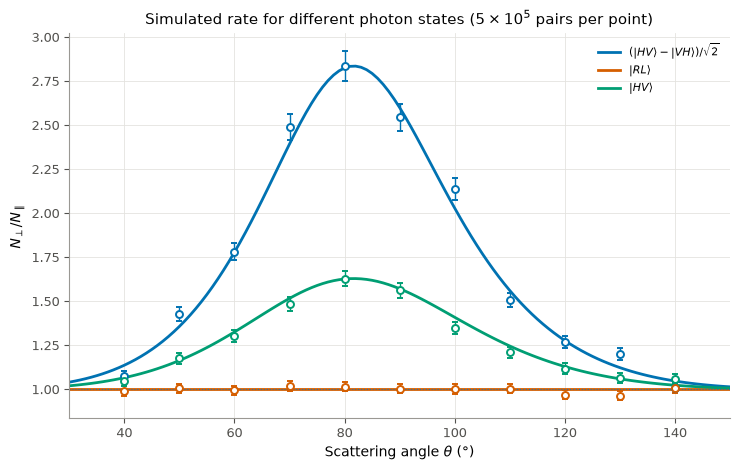

In [13]:
Number_of_simulations = 500_000

def style(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#9a9893")
    ax.tick_params(colors="#52514e", labelsize=9)
    ax.grid(True, color="#e4e3df", lw=0.6)
    ax.set_axisbelow(True)


fig, ax = plt.subplots(figsize=(7.5, 4.8))

# Smooth lines: ratio curves using Born-rule
th = np.linspace(30, 150, 121) * DEG    # degrees for smooth lines
for (name, rho), col in zip(states.items(), COLORS):
    ax.plot(th / DEG, [ratio(rho, t) for t in th], color=col, lw=2, label=name)


# Simulated experiments
th_pts = np.arange(40, 141, 10) * DEG   # degrees for experimental results
for (name, rho), col in zip(states.items(), COLORS):
    res = []
    for t in th_pts:
        pairs = run_experiment(rho, t, Number_of_simulations)   # one experiment: 3 million photon pairs at angle t
        res.append(analyse(pairs))                  # its (ratio, error)
    res = np.array(res)                             # column 0: ratios, column 1: errors
    ax.errorbar(th_pts / DEG, res[:, 0], yerr=res[:, 1], fmt="o", color=col, mfc="white", mew=1.4,
                ms=5, capsize=2, lw=1)



ax.axhline(1, lw=0.8, ls=":")
ax.set_xlim(30, 150)
# ax.set_ylim(0.3, 3.0)
ax.set_xlabel(r"Scattering angle $\theta$ (°)")
ax.set_ylabel(r"$N_\perp / N_\parallel$")
mant, exp = f"{Number_of_simulations:.0e}".split("e")
ax.set_title(rf"Simulated rate for different photon states (${mant}\times10^{{{int(exp)}}}$ pairs per point)",
             fontsize=11)
ax.legend(frameon=False, fontsize=8, loc="upper right")
style(ax)

fig.tight_layout()

# Save as png and pdf
# for ext in ("png", "pdf"):
#     fig.savefig(f"wu_quantum_states.{ext}", dpi=300)

plt.show()

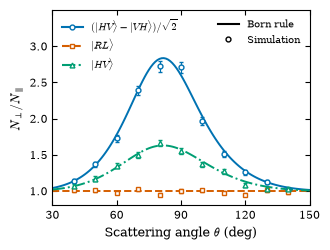

In [ ]:
# Paper-like figure

Number_of_simulations = 600_000


# LaTeX-like fonts
plt.rcParams["font.family"] = "serif"
plt.rcParams["mathtext.fontset"] = "cm"


fig, ax = plt.subplots(figsize=(3.4, 2.6))

# Exact Born-rule curves
th = np.linspace(30, 150, 121) * DEG
for (name, rho), col, ls in zip(states.items(), COLORS, LINES):
    ax.plot(th / DEG, [ratio(rho, t) for t in th], color=col, ls=ls, lw=1.4)

# Simulated experiments
th_pts = np.arange(40, 141, 10) * DEG
for (name, rho), col, mk in zip(states.items(), COLORS, MARKERS):
    res = []
    for t in th_pts:
        pairs = run_experiment(rho, t, Number_of_simulations)  
        res.append(analyse(pairs))                             
    res = np.array(res)
    ax.errorbar(th_pts / DEG, res[:, 0], yerr=res[:, 1], fmt=mk, color=col, mfc="white",
                ms=3.5, capsize=1.5, elinewidth=0.8)

# Reference line, axes and labels
# ax.axhline(1, color="grey", lw=0.6, ls=":")
ax.set_xlim(30, 150)
ax.set_ylim(0.8, 3.5)                        # extra space at the top for the legends
ax.set_xticks([30, 60, 90, 120, 150])
ax.set_yticks([1.0, 1.5, 2.0, 2.5, 3.0])
ax.tick_params(direction="in", top=True, right=True, labelsize=8)   # ticks inside, on all four sides
ax.set_xlabel(r"Scattering angle $\theta$ (deg)", fontsize=9)
ax.set_ylabel(r"$N_\perp / N_\parallel$", fontsize=9)

# Legend 1 (top left)
state_entries = [Line2D([], [], color=col, ls=ls, marker=mk, mfc="white", ms=3.5, label=name)
                 for name, col, ls, mk in zip(states, COLORS, LINES, MARKERS)]
legend1 = ax.legend(handles=state_entries, loc="upper left", fontsize=7.5, frameon=False)
ax.add_artist(legend1)                        # needed so the second legend doesn't replace the first

# Legend 2 (top right): what lines and markers mean
key_entries = [Line2D([], [], color="black", ls="-", label="Born rule"),
               Line2D([], [], color="black", ls="none", marker="o", mfc="white", ms=3.5, label="Simulation")]
ax.legend(handles=key_entries, loc="upper right", fontsize=7.5, frameon=False)

fig.tight_layout()
# fig.savefig("wu_quantum_states.pdf", bbox_inches="tight")
plt.show()